In [1]:
from langchain.agents.middleware import dynamic_prompt
from langchain.chat_models import init_chat_model

profile = {
    "name": "jiarui",
    "full_name": "raojiarui",
    "user_profile_background": "Senior software engineer and also a university student"
}
prompt_instructions = {
    "triage_rules": {
        # 分类规则
        "ignore": "Marketing newsletters, spam emails, mass company announcements",
        "notify": "Team member out sick, build system notifications, project status updates",
        "respond": "Direct questions from team members, meeting requests, critical bug reports",
    },
    "agent_instructions": "Use these tools when appropriate to help manage emails.",
}
# 创建示例邮件
email = {
    "from": "Alice Smith <alice.smith@company.com>",
    "to": "John Doe <john.doe@company.com>",
    "subject": "Quick question about API documentation",
    "body": """
    Hi John,

    I was reviewing the API documentation for the new authentication service and noticed a few endpoints are missing. Specifically, I'm looking at:

    - /auth/refresh
    - /auth/validate

    Thanks!
    Alice
    """
}


In [2]:
from pydantic import BaseModel, Field
from typing import Literal, TypedDict, Annotated

class Router(BaseModel):
    """Analyze the unread email and route it according to its content"""

    reasoning : str = Field(
        # 语言模型在此生成决策
        description="Step-by-Step reasoning behind the classification."
    )

    classification: Literal["ignore", "respond", "notify"] = Field(
        description="The classification of an email: ignore for irrelevant emails,notify for important information that doesn't need a response,respond for emails that need a reply",
    )

In [65]:
from langchain.chat_models import init_chat_model

llm = init_chat_model(
    "deepseek-v4-flash",
    extra_body={
        "thinking" :{
            "type": "disabled"
        }
    }
)
llm_router = llm.with_structured_output(Router)

In [66]:
from prompts import triage_user_prompt, triage_system_prompt

In [67]:
from langchain_core.tools import tool

In [68]:
@tool  # 暂不实现任何逻辑
def write_email(to: str, subject: str, content: str) -> str:
    """Writer and send an email."""
    # Placeholder response - in real app would send email
    # 需要完成发送邮箱的邮箱地址，邮箱主题和邮箱内容
    return f"Email sent to {to} with subject '{subject}'"


@tool
def schedule_meeting(
        attendees: list[str],
        subject: str,
        duration_minutes: int,
        preferred_day: str  # 日历会议
) -> str:
    """Schedule a calendar meeting."""
    return f"Meeting '{subject}' scheduled for {preferred_day} with {len(attendees)} attendees"


@tool
def check_calendar_availability(day: str) -> str:
    """Check calendar availability for a given day."""
    return f"Available times on {day}: 9:00 AM, 2:00 PM, 4:00 PM"

In [69]:
# 设置长期记忆存储
from langgraph.store.memory import InMemoryStore

In [70]:
store = InMemoryStore(
    index={"embed":"ollama:qwen3-embedding:0.6b"} #用于索引存储记忆
)

In [71]:
from langmem import create_manage_memory_tool, create_search_memory_tool

In [72]:
manage_memory_tool = create_manage_memory_tool(
    namespace=(
        "email_assistant", # 命名空间值
        "{langgraph_user_id}",
        "collection"
    )
)

search_memory_tool = create_search_memory_tool(
    namespace=(
        "email_assistant",
        "{langgraph_user_id}",
        "collection"
    )
)

In [73]:
manage_memory_tool.name

'manage_memory'

In [74]:
print(manage_memory_tool.description)

Create, update, or delete a memory to persist across conversations.
Include the MEMORY ID when updating or deleting a MEMORY. Omit when creating a new MEMORY - it will be created for you.
Proactively call this tool when you:

1. Identify a new USER preference.
2. Receive an explicit USER request to remember something or otherwise alter your behavior.
3. Are working and want to record important context.
4. Identify that an existing MEMORY is incorrect or outdated.


In [75]:
print(manage_memory_tool.args)

{'content': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'title': 'Content'}, 'action': {'default': 'create', 'enum': ['create', 'update', 'delete'], 'title': 'Action', 'type': 'string'}, 'id': {'anyOf': [{'format': 'uuid', 'type': 'string'}, {'type': 'null'}], 'default': None, 'title': 'Id'}}


In [76]:
print(search_memory_tool.description)

Search your long-term memories for information relevant to your current context.


In [77]:
print(search_memory_tool.args) # 返回记忆数量的限制，偏移量和过滤条件

{'query': {'title': 'Query', 'type': 'string'}, 'limit': {'default': 10, 'title': 'Limit', 'type': 'integer'}, 'offset': {'default': 0, 'title': 'Offset', 'type': 'integer'}, 'filter': {'anyOf': [{'additionalProperties': True, 'type': 'object'}, {'type': 'null'}], 'default': None, 'title': 'Filter'}}


In [78]:
# 添加新的系统提示词
agent_system_prompt_memory = """
< Role >
You are {full_name}'s executive assistant. You are a top-notch executive assistant who cares about {name} performing as well as possible.
</ Role >

< Tools >
You have access to the following tools to help manage {name}'s communications and schedule:

1. write_email(to, subject, content) - Send emails to specified recipients
2. schedule_meeting(attendees, subject, duration_minutes, preferred_day) - Schedule calendar meetings
3. check_calendar_availability(day) - Check available time slots for a given day
4. manage_memory - Store any relevant information about contacts, actions, discussion, etc. in memory for future reference
5. search_memory - Search for any relevant information that may have been stored in memory
</ Tools >

< Instructions >
{instructions}
</ Instructions >
"""

In [79]:
from langchain.agents.middleware import dynamic_prompt

@dynamic_prompt
def create_prompt(state):
    # 只返回字符串
    return agent_system_prompt_memory.format(
            instructions=prompt_instructions["agent_instructions"],
            **profile
    )

In [80]:
# 创建react代理函数
from langchain.agents import create_agent

In [81]:
tools = [
    write_email,
    schedule_meeting,
    check_calendar_availability,
    manage_memory_tool,
    search_memory_tool
]

response_agent = create_agent(
    "deepseek-v4-flash",
    tools=tools,
    middleware=[create_prompt],
    store=store
)

In [82]:
# define a config
config = {"configurable" : {"langgraph_user_id": "raojiarui"}}

In [83]:
response = response_agent.invoke(
    {"messages": [{"role": "user", "content":"duwenxin is my friend"}]},
    config=config
)

In [84]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

duwenxin is my friend
================================== Ai Message ==================================

I'll save this to memory so I remember it for future conversations.
Tool Calls:
  manage_memory (call_00_sjRldkxLCTXCWpQzrFMU5731)
 Call ID: call_00_sjRldkxLCTXCWpQzrFMU5731
  Args:
    action: create
    content: duwenxin is jiarui's friend.
================================= Tool Message =================================
Name: manage_memory

created memory b73da2ea-cde1-47ef-87ee-1cb2f3f314f5
================================== Ai Message ==================================

Got it — I've noted that duwenxin is your friend. Is there anything you'd like me to do with this, such as sending them an email or setting up a meeting?


In [85]:
response = response_agent.invoke(
    {"messages": [{
        "role" : "user",
        "content" : "who is duwenxin",
    }]},
    config=config
)

In [86]:
for i in response["messages"]:
    i.pretty_print()

================================ Human Message =================================

who is duwenxin
================================== Ai Message ==================================
Tool Calls:
  search_memory (call_00_wwtInNCV9k3JS7V4LHxn6443)
 Call ID: call_00_wwtInNCV9k3JS7V4LHxn6443
  Args:
    query: duwenxin
================================= Tool Message =================================
Name: search_memory

[{"namespace":["email_assistant","raojiarui","collection"],"key":"b73da2ea-cde1-47ef-87ee-1cb2f3f314f5","value":{"content":"duwenxin is jiarui's friend."},"created_at":"2026-10-08T14:08:01.486836+00:00","updated_at":"2026-10-08T14:08:01.486836+00:00","score":0.5683998158664079}]
================================== Ai Message ==================================

Based on what I have in memory, **Duwenxin is a friend of Jiarui's.**

That's the only note I have on file for them. Would you like me to do anything involving Duwenxin — like sending an email or scheduling a meeting? If so

In [87]:
store.list_namespaces()

[('email_assistant', 'raojiarui', 'collection')]

In [88]:
store.search(('email_assistant', 'raojiarui', 'collection'), query="duwenxin") # 当为传入查询参数时，score值为none

[Item(namespace=['email_assistant', 'raojiarui', 'collection'], key='b73da2ea-cde1-47ef-87ee-1cb2f3f314f5', value={'content': "duwenxin is jiarui's friend."}, created_at='2026-10-08T14:08:01.486836+00:00', updated_at='2026-10-08T14:08:01.486836+00:00', score=0.5683998158664079)]

In [89]:
# 创建代理的剩余部分
from langgraph.graph import add_messages

class State(TypedDict):
    email_input : dict
    messages : Annotated[list, add_messages]

In [90]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from typing import Literal
from IPython.display import Image, display

In [91]:
# 构建代理
def triage_router(state : State) -> Command[
    Literal["response_agent", "__end__"]
]:
    # load the info
    author = state['email_input']['author']
    to = state['email_input']['to']
    subject = state['email_input']['subject']
    email_thread = state['email_input']['email_thread']

    system_prompt = triage_system_prompt.format(
        full_name = profile["full_name"], #
        name=profile["name"],
        user_profile_background=profile["user_profile_background"],
        triage_no=prompt_instructions["triage_rules"]["ignore"],
        triage_notify=prompt_instructions["triage_rules"]["notify"],
        triage_email=prompt_instructions["triage_rules"]["respond"],
        examples=None
    )

    user_prompt = triage_user_prompt.format(
        author=author,
        to=to,
        subject=subject,
        email_thread=email_thread
    )

    result = llm_router.invoke(
        # llm_router是带有分类输出的llm，将llm的输出格式化为route
        [
            ("system", system_prompt),
            ("user", user_prompt)
            # {"role" : "system", "content": system_prompt},
            # {"role": "user", "content": user_prompt}
        ]
    )

    # 处理三种可能的结果
    if result.classification == "respond":
        print("📧 Classification: RESPOND - This email requires a response")
        goto = "response_agent"
        # 跳转到响应agent的节点
        update = {
            # 更新状态
            "messages": [
                # {
                #     "role": "user",
                #     "content": f"Respond to the email {state['email_input']}",
                # }
                ("user", f"Respond to email {state['email_input']}")
            ]
        }
    elif result.classification == "ignore":
        print("🚫 Classification: IGNORE - This email can be safely ignored")
        update = None
        goto = END
    elif result.classification == "notify":
        # If real life, this would do something else
        print("🔔 Classification: NOTIFY - This email contains important information")
        update = None
        goto = END
    else:
        raise ValueError(f"Invalid classification: {result.classification}")
    return Command(goto=goto, update=update)

In [92]:
email_agent = StateGraph(State)
email_agent = email_agent.add_node(triage_router)
email_agent = email_agent.add_node("response_agent", response_agent)
email_agent = email_agent.add_edge(START, "triage_router")
email_agent = email_agent.compile(store=store)

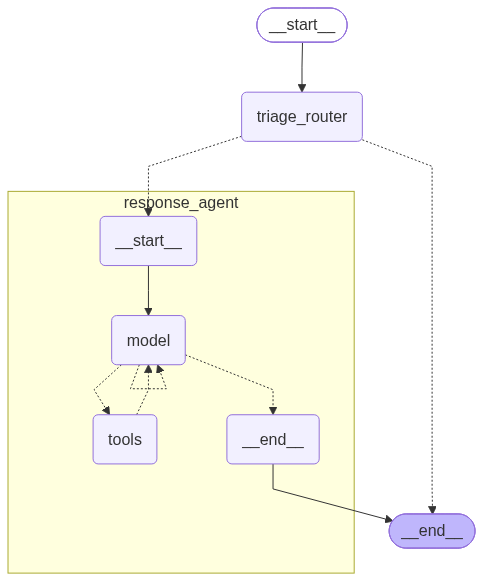

In [93]:
display(Image(email_agent.get_graph(xray=True).draw_mermaid_png()))

In [94]:
email_input = {
    "author": "Alice Smith <alice.smith@company.com>",
    "to": "John Doe <john.doe@company.com>",
    "subject": "Quick question about API documentation",
    "email_thread": """Hi John,

I was reviewing the API documentation for the new authentication service and noticed a few endpoints are missing. Specifically, I'm looking at:

- /auth/refresh
- /auth/validate

Thanks!
Alice""",
}

In [95]:
response = email_agent.invoke(
    {"email_input" : email_input},
    config=config
)

📧 Classification: RESPOND - This email requires a response


In [96]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Respond to email {'author': 'Alice Smith <alice.smith@company.com>', 'to': 'John Doe <john.doe@company.com>', 'subject': 'Quick question about API documentation', 'email_thread': "Hi John,\n\nI was reviewing the API documentation for the new authentication service and noticed a few endpoints are missing. Specifically, I'm looking at:\n\n- /auth/refresh\n- /auth/validate\n\nThanks!\nAlice"}
================================== Ai Message ==================================
Tool Calls:
  search_memory (call_00_5dQvJlrqL4H7N7wxz9se8674)
 Call ID: call_00_5dQvJlrqL4H7N7wxz9se8674
  Args:
    query: Alice Smith John Doe API documentation authentication service
  search_memory (call_01_7lVsgSgb1o9TeHMV03ko2124)
 Call ID: call_01_7lVsgSgb1o9TeHMV03ko2124
  Args:
    query: John Doe email preferences communication style
================================= Tool Message =================================
Name: search_mem

In [97]:
email_input = {
    "author": "Alice Smith <alice.smith@company.com>",
    "to": "John Doe <john.doe@company.com>",
    "subject": "Follow up",
    "email_thread": """Hi John,

Any update on my previous ask?""",
}

In [98]:
repsonse = email_agent.invoke({"email_input":email_input}, config=config)

📧 Classification: RESPOND - This email requires a response


In [99]:
for m in repsonse["messages"]:
    m.pretty_print()

================================ Human Message =================================

Respond to email {'author': 'Alice Smith <alice.smith@company.com>', 'to': 'John Doe <john.doe@company.com>', 'subject': 'Follow up', 'email_thread': 'Hi John,\n\nAny update on my previous ask?'}
================================== Ai Message ==================================

I'll help respond to this email. Let me first check my memory for relevant context about this conversation and the people involved.
Tool Calls:
  search_memory (call_00_pbaKejm8zzOVolRup3lp1681)
 Call ID: call_00_pbaKejm8zzOVolRup3lp1681
  Args:
    query: Alice Smith previous ask follow up
  search_memory (call_01_RRT4r0THk1JCb7ACD1wa1341)
 Call ID: call_01_RRT4r0THk1JCb7ACD1wa1341
  Args:
    query: John Doe email thread update
================================= Tool Message =================================
Name: search_memory

[{"namespace":["email_assistant","raojiarui","collection"],"key":"6095b927-b859-4ca4-9468-a060656a6a96",